# Homework #2: Titanic 생존 예측

승객의 10개 특성으로 생존을 예측하는 MLP를 구성하고 36개 하이퍼파라미터 조합을 비교하였다.
검증 손실로 선택한 설정의 최적 epoch 모델을 복원하여 Kaggle에 제출하였다.

EarlyStopping을 포함한 전처리·모델·훈련·실험 반복·결과 집계·예측은 이 노트북의 코드 셀에 직접 정의한다.
원본 CSV와 완료한 실험 산출물은 데이터 파일로 읽는다.
기본 실행은 이미 완료한 실험을 불러와 분석하고 예측을 재현한다.
재훈련 스위치를 켜면 아래에 정의한 코드가 새 모델을 훈련한다.

코드의 [핵심] 주석은 학습과 추론의 의미를, [실행 보조] 주석은 경로·설정·저장·검증·시각화의 목적과 결과를 설명한다.

## 0. 베이스 코드 활용 및 변경 사항

기준: _01_code/_08_learning_and_optimization/c_my_model_training_with_argparse_wandb.py.
아래 행 번호는 이번 과제에서 확인한 원본 기준이다.

| 원본 행 | 이 노트북의 구현 | 유지한 부분과 필요한 변경 |
|---|---|---|
| 19~29 | get_data | 학습/검증 DataLoader 유지, California 대신 Titanic 및 고정 RNG |
| 32~46 | MyModel | Linear 3개와 은닉층 20/20 유지, 활성화 함수 4종 선택 |
| 49~53 | get_model_and_optimizer | SGD 유지, 입력 8→10, 출력 1 유지 |
| 56~73 | training_loop의 학습 부분 | epoch/배치 반복과 zero_grad→backward→step 유지, MSE→BCE |
| 75~83 | training_loop의 검증 부분 | no_grad 유지, eval 및 표본 수 가중 평균 보완 |
| 85~89 | training_loop의 run.log | Epoch/Training loss/Validation loss 유지, accuracy/F1 추가 |
| 100~108, 127~139 | main | config 및 데이터→모델→학습 호출 순서 유지 |
| 110~125 | main의 W&B 설정 | wandb.init 및 Epoch 기준 두 loss 지표 재사용 |
| 143~160 | 아래 설정 셀 | CLI argparse 대신 명시적 변수와 SimpleNamespace 사용 |
| 추가 구현 | EarlyStopping 호출/복원/추론 | 요구사항 3의 최적 epoch 선택과 submission.csv 생성 |
| 추가 보조 | 기록 저장/실험 반복/집계/그래프 | 재현과 결과 설명을 위한 코드로 별도 표시 |

MLP 구조와 SGD 학습 원리는 유지했다. 이진 분류에 필요한 손실·입력 변경, 활성화 함수 비교,
Early Stopping은 과제에 필요한 확장이다. 데이터 클래스와 전처리 6단계는 강의의
_03_homeworks/homework_2/titanic_dataset.py를 바탕으로 아래에 직접 작성하였다.
기존 파일을 불러 실행하거나 소스 출력으로 구현을 대신하지 않는다.

In [ ]:
import json
import math
from datetime import datetime
from itertools import product
from pathlib import Path
from types import SimpleNamespace
from uuid import uuid4

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn, optim
from torch.utils.data import Dataset, DataLoader, random_split
from sklearn.preprocessing import LabelEncoder
import wandb
from IPython.display import Markdown, display

# [실행 보조: 경로]
# 프로젝트 루트에서 실행한다. 아래 폴더에서는 .py가 아닌 데이터와 저장 결과만 읽는다.
ROOT = Path.cwd()
DATA_DIR = ROOT / "_03_homeworks/homework_2"
RESULTS = DATA_DIR / "results"
assert (DATA_DIR / "train.csv").is_file(), "프로젝트 루트에서 노트북을 실행해야 함"

# [실행 보조: 학습 설정]
# 원본의 argparse를 대체한다. 모든 조합에서 공통 조건을 고정해 비교한다.
SETTINGS = dict(epochs=10_000, batch_size=128, learning_rate=1e-3,
                activation="relu", seed=42, early_stop_patience=100,
                early_stop_delta=1e-5)
RUN_BASELINE = False
RUN_GRID = False
RUN_FINAL = False
USE_WANDB = True  # 재훈련 스위치가 True일 때만 새 W&B run을 생성한다.

# [실행 보조: 재실행 결과 분리]
# 스위치를 켜면 고유 폴더에 새 결과를 저장한다. 기본 False에서는 기존 실험을 읽는다.
REPEAT_ID = datetime.now().strftime("%Y%m%d_%H%M%S") + "_" + uuid4().hex[:8]
NEW_RESULTS = RESULTS / ("notebook_" + REPEAT_ID)
torch.set_num_threads(1)
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 40)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
print("PyTorch:", torch.__version__)
print("데이터 폴더:", DATA_DIR)
print("재훈련 스위치:", RUN_BASELINE, RUN_GRID, RUN_FINAL)

/Users/jyj/git/link_dl/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


PyTorch: 2.8.0
데이터 폴더: /Users/jyj/git/link_dl/_03_homeworks/homework_2
재훈련 스위치: False False False


## 1. 데이터 클래스와 전처리

타깃은 Survived=0(사망), 1(생존)이다. 입력은 Pclass, Sex, Age, SibSp, Parch, Fare,
Embarked, title, family_num, alone의 10개다.
강의 전처리를 유지하며 요금 결측값에는 객실 등급별 평균,
나이 결측값에는 호칭별 중앙값을 반올림한 값을 사용한다.

In [2]:
# [핵심: 강의 TitanicDataset/TitanicTestDataset 활용]
# DataLoader가 input/target 딕셔너리를 배치로 묶을 수 있도록 Dataset 인터페이스를 구현한다.
class TitanicDataset(Dataset):
    """특성 X와 정답 y를 받아 float 입력과 정수 타깃 표본을 반환한다."""
    def __init__(self, X, y):
        self.X = torch.FloatTensor(X)  # 표본 하나의 shape=(10,)
        self.y = torch.LongTensor(y)   # BCE 입력으로 바꾸는 작업은 학습 단계에서 수행한다.

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return {"input": self.X[idx], "target": self.y[idx]}


class TitanicTestDataset(Dataset):
    """정답이 없는 테스트 X를 받아 input만 있는 표본을 반환한다."""
    def __init__(self, X):
        self.X = torch.FloatTensor(X)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return {"input": self.X[idx]}

print("Dataset 정의 완료: 입력 10개, 학습 타깃 정수 0/1")

Dataset 정의 완료: 입력 10개, 학습 타깃 정수 0/1


In [3]:
# [핵심: 강의 전처리 6단계]
# 각 함수는 DataFrame을 받아 다음 단계에 필요한 열을 추가/변환한 DataFrame을 반환한다.
def get_preprocessed_dataset_1(all_df):
    """Pclass별 Fare 평균으로 누락 요금을 채운다."""
    fare_mean = all_df[["Pclass", "Fare"]].groupby("Pclass").mean().reset_index()
    fare_mean.columns = ["Pclass", "Fare_mean"]
    all_df = pd.merge(all_df, fare_mean, on="Pclass", how="left")
    all_df.loc[all_df["Fare"].isnull(), "Fare"] = all_df["Fare_mean"]
    return all_df.drop(columns=["Fare_mean"])


def get_preprocessed_dataset_2(all_df):
    """이름을 성/호칭/이름으로 나누어 호칭별 나이 보간에 사용한다."""
    names = all_df["Name"].str.split("[,.]", n=2, expand=True)
    names.columns = ["family_name", "title", "name"]
    for column in names.columns:
        names[column] = names[column].str.strip()
    return pd.concat([all_df, names], axis=1)


def get_preprocessed_dataset_3(all_df):
    """호칭별 나이 중앙값을 반올림하여 Age 결측값을 채운다."""
    # 평균(mean)이 아니라 중앙값(median)을 사용한다.
    ages = all_df[["title", "Age"]].groupby("title").median().round().reset_index()
    ages.columns = ["title", "title_age_mean"]
    all_df = pd.merge(all_df, ages, on="title", how="left")
    all_df.loc[all_df["Age"].isnull(), "Age"] = all_df["title_age_mean"]
    return all_df.drop(columns=["title_age_mean"])


def get_preprocessed_dataset_4(all_df):
    """가족 수/단독 탑승 특성을 만들고 학습에 쓰지 않는 식별자/문자열을 제거한다."""
    all_df["family_num"] = all_df["Parch"] + all_df["SibSp"]
    all_df.loc[all_df["family_num"] == 0, "alone"] = 1
    all_df["alone"] = all_df["alone"].fillna(0)
    return all_df.drop(
        columns=["PassengerId", "Name", "family_name", "name", "Ticket", "Cabin"])


def get_preprocessed_dataset_5(all_df):
    """희귀 호칭을 other로 묶고 탑승지 누락은 missing 범주로 남긴다."""
    common_titles = ["Mr", "Miss", "Mrs", "Master"]
    all_df.loc[~all_df["title"].isin(common_titles), "title"] = "other"
    all_df["Embarked"] = all_df["Embarked"].fillna("missing")
    return all_df


def get_preprocessed_dataset_6(all_df):
    """성별/탑승지/호칭 문자열을 LabelEncoder 정수 코드로 변환한다."""
    # 기존 전처리와 동일하게 범주별 정렬 순서로 코드를 부여한다.
    categories = all_df.columns[all_df.dtypes == "object"]
    for column in categories:
        all_df[column] = LabelEncoder().fit_transform(all_df[column])
    return all_df

print("전처리 6단계 정의 완료")

전처리 6단계 정의 완료


In [4]:
# [핵심: 원본 데이터 로딩 및 분할]
def get_preprocessed_dataset(seed=42):
    """train/test CSV를 전처리하여 학습/검증/테스트 Dataset 3개를 반환한다."""
    train_df = pd.read_csv(DATA_DIR / "train.csv")
    test_df = pd.read_csv(DATA_DIR / "test.csv")
    # 강의 코드의 합동 전처리를 유지한다. 엄격한 평가에서의 한계는 고찰에 적었다.
    all_df = pd.concat([train_df, test_df], sort=False)
    for preprocess in (
        get_preprocessed_dataset_1, get_preprocessed_dataset_2,
        get_preprocessed_dataset_3, get_preprocessed_dataset_4,
        get_preprocessed_dataset_5, get_preprocessed_dataset_6,
    ):
        all_df = preprocess(all_df)
    train_X = all_df[all_df["Survived"].notna()].drop(columns="Survived").reset_index(drop=True)
    test_X = all_df[all_df["Survived"].isna()].drop(columns="Survived").reset_index(drop=True)
    dataset = TitanicDataset(train_X.values, train_df["Survived"].values)
    # 분할 전용 RNG를 사용해 다른 셀에서 난수를 소비해도 같은 713/178 분할을 얻는다.
    train_dataset, validation_dataset = random_split(
        dataset, [0.8, 0.2], generator=torch.Generator().manual_seed(seed))
    return train_dataset, validation_dataset, TitanicTestDataset(test_X.values)


# [핵심: 베이스 19~29행 get_data]
# 두 DataLoader의 구조를 유지하고, 데이터와 셔플 난수 생성기만 Titanic에 맞춘다.
def get_data(run):
    """run.config의 seed/batch_size로 학습 및 검증 DataLoader를 반환한다."""
    train_dataset, validation_dataset, _ = get_preprocessed_dataset(run.config.seed)
    train_loader = DataLoader(
        train_dataset, batch_size=run.config.batch_size, shuffle=True,
        generator=torch.Generator().manual_seed(run.config.seed))
    validation_loader = DataLoader(validation_dataset, batch_size=len(validation_dataset))
    return train_loader, validation_loader


# [실행 보조: 데이터 확인]
# 실제 shape와 결측값/타깃 정렬을 검사하고 전처리 예시를 출력한다. 파일은 변경하지 않는다.
train_set, validation_set, test_set = get_preprocessed_dataset()
raw_train = pd.read_csv(DATA_DIR / "train.csv")
raw_test = pd.read_csv(DATA_DIR / "test.csv")
columns = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare",
           "Embarked", "title", "family_num", "alone"]
assert (len(train_set), len(validation_set), len(test_set)) == (713, 178, 418)
assert torch.isfinite(train_set.dataset.X).all() and torch.isfinite(test_set.X).all()
assert np.array_equal(train_set.dataset.y.numpy(), raw_train.Survived.to_numpy())
display(pd.DataFrame({"분할": ["train", "validation", "test"],
                      "표본 수": [713, 178, 418], "입력 특성 수": [10, 10, 10]}))
display(pd.DataFrame(train_set.dataset.X[:5].numpy(), columns=columns))
print("입력/타깃 정렬 및 결측값 검사 통과")

,분할,표본 수,입력 특성 수
0,train,713,10
1,validation,178,10
2,test,418,10


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,title,family_num,alone
0,3.0,1.0,22.0,1.0,0.0,7.250000,2.0,2.0,1.0,0.0
1,1.0,0.0,38.0,1.0,0.0,71.283302,0.0,3.0,1.0,0.0
2,3.0,0.0,26.0,0.0,0.0,7.925000,2.0,1.0,0.0,1.0
3,1.0,0.0,35.0,1.0,0.0,53.099998,2.0,3.0,1.0,0.0
4,3.0,1.0,35.0,0.0,0.0,8.050000,2.0,2.0,0.0,1.0


입력/타깃 정렬 및 결측값 검사 통과


## 2. 모델과 지표

베이스의 은닉층 20/20과 SGD를 유지한다. Titanic 입력은 10개이므로 입력 차원만 바꾼다.
출력은 logit 하나이며, BCEWithLogitsLoss가 sigmoid 연산을 포함한다.
출력층에 sigmoid를 다시 붙이지 않는다.

In [5]:
# [핵심: 베이스 32~46행 MyModel]
# Linear 3개의 연결 구조를 유지하고 두 은닉층의 활성화 함수만 선택 가능하게 만든다.
class MyModel(nn.Module):
    """입력 (batch,10)을 받아 생존 logit (batch,1)을 반환하는 MLP."""
    def __init__(self, n_input, n_output, run):
        super().__init__()
        activation_fn = {
            "sigmoid": nn.Sigmoid, "relu": nn.ReLU,
            "elu": nn.ELU, "leaky_relu": nn.LeakyReLU,
        }[run.config.activation]
        self.model = nn.Sequential(
            nn.Linear(n_input, run.config.n_hidden_unit_list[0]),
            activation_fn(),
            nn.Linear(run.config.n_hidden_unit_list[0], run.config.n_hidden_unit_list[1]),
            activation_fn(),
            nn.Linear(run.config.n_hidden_unit_list[1], n_output),
        )

    def forward(self, x):
        return self.model(x)


# [핵심: 베이스 49~53행]
def get_model_and_optimizer(run):
    """Titanic MLP와 설정된 학습률의 SGD optimizer를 반환한다."""
    model = MyModel(n_input=10, n_output=1, run=run)
    optimizer = optim.SGD(model.parameters(), lr=run.config.learning_rate)
    return model, optimizer


# [핵심: 추가 평가 지표]
def binary_accuracy_f1(logits, targets):
    """logit/타깃에서 정확도(%)와 생존 클래스 F1(0~1)을 반환한다."""
    predicted = logits.reshape(-1) >= 0  # sigmoid 확률 0.5 이상과 같은 판정이다.
    actual = targets.reshape(-1).bool()
    accuracy = 100.0 * (predicted == actual).float().mean().item()
    tp = (predicted & actual).sum().item()
    fp = (predicted & ~actual).sum().item()
    fn = (~predicted & actual).sum().item()
    denominator = 2 * tp + fp + fn
    f1 = 0.0 if denominator == 0 else 2 * tp / denominator
    return accuracy, f1


# [실행 보조: 모델 구조 출력]
# 출력 shape/파라미터 수를 확인한다. 실험 main에서 seed를 다시 설정하므로 초기화에 영향 없다.
example_run = SimpleNamespace(config=SimpleNamespace(
    activation="relu", n_hidden_unit_list=[20, 20]))
example_model = MyModel(10, 1, example_run)
print(example_model)
print("파라미터 수:", sum(p.numel() for p in example_model.parameters()))
print("출력 shape:", tuple(example_model(torch.zeros(2, 10)).shape))

MyModel(
  (model): Sequential(
    (0): Linear(in_features=10, out_features=20, bias=True)
    (1): ReLU()
    (2): Linear(in_features=20, out_features=20, bias=True)
    (3): ReLU()
    (4): Linear(in_features=20, out_features=1, bias=True)
  )
)
파라미터 수: 661
출력 shape: (2, 1)


## 3. 학습·검증과 Early Stopping

학습 손실은 epoch 내에서 갱신되는 모델의 배치별 손실이다. 검증 손실은 epoch 종료 시점의
고정된 모델에서 계산한다. 배치별 평균을 다시 단순 평균하지 않고 표본 수로 가중한다.

EarlyStopping은 아래 코드 셀에 직접 구현한다. 원본은 [linklab/link_dl](https://github.com/linklab/link_dl)의
_01_code/_99_common_utils/early_stopping.py이다. 원본의 중단 기준은 유지하고, 첫 호출에서
loss만 기록하던 부분을 가중치도 저장하도록 보완했다. 이후 개선이 없어도 복원할 파일이 존재한다.
경로 구성은 os.path.join 대신 이미 가져온 Path를 사용하고, 중복 loss 대입은 저장 함수로 통합했다.
저장된 검증 loss보다 delta=0.00001을 초과하여 개선되면 다시 저장한다.
patience=100 동안 개선되지 않으면 종료한다.
따라서 종료 epoch와 예측용 저장 epoch는 다를 수 있다.
아주 작은 개선은 delta 때문에 무시될 수 있으므로 보고와 선택에는 실제 저장 모델의 loss를 사용한다.

In [6]:
# [핵심: EarlyStopping 원본 출처]
# upstream: https://github.com/linklab/link_dl
# 원본 경로: _01_code/_99_common_utils/early_stopping.py
# 원본의 delta 비교와 patience 카운터를 유지한다.
# 변경: 첫 호출도 save_checkpoint로 저장한다. 이후 개선이 없어도 복원 파일이 존재하게 한다.
class EarlyStopping:
    """검증 loss 개선을 감시하고 최적 가중치를 저장하며 종료 여부를 반환한다."""

    def __init__(self, patience=10, delta=0.00001, project_name=None,
                 checkpoint_file_path=None, run_time_str=None):
        self.patience = patience
        self.counter = 0
        self.delta = delta
        self.val_loss_min = None
        # [실행 보조: 저장 경로]
        # 호출자가 만든 폴더에 실행별 파일과 공통 latest 파일을 저장한다.
        self.file_path = str(Path(checkpoint_file_path) /
                             f"{project_name}_checkpoint_{run_time_str}.pt")
        self.latest_file_path = str(Path(checkpoint_file_path) /
                                    f"{project_name}_checkpoint_latest.pt")

    def check_and_save(self, new_validation_loss, model):
        """현재 loss와 모델을 받아 (상태 메시지, 학습 종료 여부)를 반환한다."""
        early_stop = False
        if self.val_loss_min is None:
            # 첫 epoch가 최적일 수 있으므로 loss뿐 아니라 가중치도 보관한다.
            self.save_checkpoint(new_validation_loss, model)
            message = "Early stopping is stated!"
        elif new_validation_loss < self.val_loss_min - self.delta:
            message = (f"V_loss decreased ({self.val_loss_min:7.5f} --> "
                       f"{new_validation_loss:7.5f}). Saving model...")
            self.save_checkpoint(new_validation_loss, model)
            self.counter = 0
        else:
            # delta를 초과하는 개선이 없으면 누적하고 patience에 도달하면 종료한다.
            self.counter += 1
            message = f"Early stopping counter: {self.counter} out of {self.patience}"
            if self.counter >= self.patience:
                early_stop = True
                message += " *** TRAIN EARLY STOPPED! ***"
        return message, early_stop

    def save_checkpoint(self, val_loss, model):
        """모델 state_dict 두 파일을 저장하고 저장 시점의 검증 loss를 기록한다."""
        # [실행 보조: 파일 저장]
        # 같은 경로는 덮어쓴다. 추론에는 다른 실행과 공유하는 latest가 아닌 실행별 파일을 쓴다.
        torch.save(model.state_dict(), self.file_path)
        torch.save(model.state_dict(), self.latest_file_path)
        self.val_loss_min = val_loss


# [핵심: 베이스 56~97행 training_loop]
# epoch/배치 반복, 순전파, 역전파, no_grad 검증과 run.log 흐름을 유지한다.
def training_loop(model, optimizer, train_data_loader, validation_data_loader, run,
                  checkpoint_dir, run_time_str):
    """모델을 훈련하고 저장된 최적 epoch의 지표, 경로, epoch별 history를 반환한다."""
    # [실행 보조: 체크포인트 출력]
    # EarlyStopping이 저장할 디렉터리를 준비한다. 실험별 파일명을 사용해 모델을 구별한다.
    Path(checkpoint_dir).mkdir(parents=True, exist_ok=True)
    early_stopping = EarlyStopping(
        patience=run.config.early_stop_patience, delta=run.config.early_stop_delta,
        project_name="titanic", checkpoint_file_path=str(checkpoint_dir),
        run_time_str=run_time_str)
    if run.config.epochs < 1 or not len(train_data_loader.dataset) or not len(validation_data_loader.dataset):
        raise ValueError("양수 epoch와 비어 있지 않은 데이터가 필요함")
    loss_fn = nn.BCEWithLogitsLoss()  # 회귀용 MSE를 logit 기반 이진 분류 loss로 변경한다.
    best, history = {}, []

    for epoch in range(1, run.config.epochs + 1):
        model.train()
        loss_train, num_trains = 0.0, 0
        train_logits, train_targets = [], []
        for batch in train_data_loader:
            inputs = batch["input"]
            # BCE는 출력과 같은 실수형 (batch,1) 타깃을 요구한다.
            targets = batch["target"].float().unsqueeze(1)
            logits = model(inputs)
            loss = loss_fn(logits, targets)
            # 마지막 작은 배치도 표본 수에 비례해 반영한다.
            loss_train += loss.item() * targets.numel()
            num_trains += targets.numel()
            train_logits.append(logits.detach())  # 지표 계산에 역전파 그래프를 보관하지 않는다.
            train_targets.append(targets)

            # 베이스와 동일: 누적 gradient 초기화 -> 미분 -> 파라미터 갱신.
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        train_accuracy, train_f1 = binary_accuracy_f1(
            torch.cat(train_logits), torch.cat(train_targets))
        loss_validation, num_validations = 0.0, 0
        validation_logits, validation_targets = [], []
        model.eval()  # Dropout/BatchNorm 등이 있을 때 평가 동작을 지정한다.
        with torch.no_grad():  # 검증은 파라미터를 갱신하지 않으므로 gradient 기록을 끈다.
            for batch in validation_data_loader:
                targets = batch["target"].float().unsqueeze(1)
                logits = model(batch["input"])
                loss_validation += loss_fn(logits, targets).item() * targets.numel()
                num_validations += targets.numel()
                validation_logits.append(logits)
                validation_targets.append(targets)
        validation_accuracy, validation_f1 = binary_accuracy_f1(
            torch.cat(validation_logits), torch.cat(validation_targets))
        validation_loss = loss_validation / num_validations

        # [실행 보조: 비정상 실험 검사]
        # NaN/inf 결과를 최적 모델로 선택하거나 보고서에 기록하지 않도록 중단한다.
        if not math.isfinite(validation_loss) or not math.isfinite(loss_train):
            raise ValueError(f"epoch {epoch}에서 유한하지 않은 loss 발생")
        previous_best = early_stopping.val_loss_min
        message, early_stop = early_stopping.check_and_save(validation_loss, model)
        # 가중치가 저장된 순간의 지표만 함께 보관한다. 별도의 최고 accuracy와 섞지 않는다.
        if previous_best is None or early_stopping.val_loss_min < previous_best:
            best = dict(
                best_epoch=epoch, best_validation_loss=validation_loss,
                best_validation_accuracy=validation_accuracy, best_validation_f1=validation_f1,
                checkpoint_path=str(Path(early_stopping.file_path).resolve()))

        # [핵심: 베이스 85~89행 run.log]
        # W&B와 로컬 history에 동일한 epoch 지표를 남겨 표와 그래프를 재현한다.
        metrics = {
            "Epoch": epoch, "Training loss": loss_train / num_trains,
            "Validation loss": validation_loss, "Training accuracy (%)": train_accuracy,
            "Validation accuracy (%)": validation_accuracy,
            "Training F1": train_f1, "Validation F1": validation_f1,
        }
        run.log(metrics)
        history.append(metrics)
        # [실행 보조: 진행 출력]
        # 첫/마지막/중단 epoch와 매 1000 epoch만 출력해 긴 출력으로 노트북이 채워지지 않게 한다.
        if epoch == 1 or epoch % 1000 == 0 or early_stop or epoch == run.config.epochs:
            print(f"Epoch {epoch}: train={metrics['Training loss']:.5f}, "
                  f"validation={validation_loss:.5f}, {message}")
        if early_stop:
            break
    return dict(best, stopped_epoch=epoch, history=history)

print("학습/검증/Early Stopping 함수 정의 완료")

학습/검증/Early Stopping 함수 정의 완료


## 4. W&B 실행과 결과 저장

베이스의 main은 설정을 만들고 W&B run을 연 뒤 데이터→모델→학습을 호출한다.
이 순서를 유지한다. 실험 ID와 CSV/JSON 저장은 실행 보조 함수로 분리한다.
JSON은 설정·저장 모델 성능·체크포인트·이력 경로를 연결한다.

In [7]:
# [실행 보조: 실험 설정]
def make_args(**overrides):
    """공통 설정에 지정한 변경만 적용해 main에 전달할 속성 객체를 반환한다."""
    values = dict(SETTINGS, wandb=USE_WANDB, group="hw2-notebook",
                  output_dir=NEW_RESULTS)
    values.update(overrides)
    return SimpleNamespace(**values)


# [실행 보조: 실험 산출물 저장]
def save_result(result, config, run, run_id, group, output_dir, online):
    """history CSV와 설정/성능 JSON을 생성하고 그 메타데이터를 반환한다."""
    history = result.pop("history")
    history_path = Path(output_dir) / f"{run_id}.csv"
    pd.DataFrame(history).to_csv(history_path, index=False)
    result.update(config)
    result.update(run_id=run_id, group=group, wandb_url=run.url if online else None,
                  history_path=str(history_path.resolve()),
                  hidden_sizes=config["n_hidden_unit_list"], max_epochs=config["epochs"])
    # 프로젝트 안의 경로는 상대경로로 남겨 폴더를 옮겨도 파일끼리 연결되게 한다.
    for key in ("history_path", "checkpoint_path"):
        path = Path(result[key])
        if ROOT in path.parents:
            result[key] = str(path.relative_to(ROOT))
    # summary는 체크포인트와 같은 epoch의 지표임을 이름에 명시한다.
    summary_keys = ("best_epoch", "stopped_epoch", "best_validation_loss",
                    "best_validation_accuracy", "best_validation_f1")
    run.summary.update({key: result[key] for key in summary_keys})
    metadata_path = Path(output_dir) / f"{run_id}.json"
    metadata_path.write_text(json.dumps(result, indent=2, allow_nan=False) + "\n")
    print("저장한 실험:", metadata_path)
    return result


# [핵심: 베이스 100~139행 main]
def main(args):
    """설정 args로 한 실험을 훈련하고 가중치/이력을 저장한 메타데이터를 반환한다."""
    # 같은 초기 가중치로 비교하기 위해 매 실험 시작 시 seed를 재설정한다.
    torch.manual_seed(args.seed)
    torch.set_num_threads(1)
    # [실행 보조: 실행 ID/폴더]
    # 같은 설정을 재실행해도 기존 파일을 덮어쓰지 않도록 고유 ID를 사용한다.
    run_id = (datetime.now().strftime("%Y%m%d_%H%M%S") +
              f"_{args.activation}_bs{args.batch_size}_lr{args.learning_rate:g}_" +
              uuid4().hex[:8])
    output_dir = Path(args.output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    config = dict(
        epochs=args.epochs, batch_size=args.batch_size, learning_rate=args.learning_rate,
        activation=args.activation, seed=args.seed, n_hidden_unit_list=[20, 20],
        early_stop_patience=args.early_stop_patience,
        early_stop_delta=args.early_stop_delta, optimizer="SGD")

    # [핵심: 베이스 110~125행]
    # config와 두 loss를 W&B에 기록한다. online일 때만 원격 run을 생성한다.
    with wandb.init(
        mode="online" if args.wandb else "disabled", project="my_model_training",
        notes="Titanic survival classification", tags=["my_model", "titanic"],
        name=run_id, group=args.group, config=config,
    ) as run:
        run.define_metric("Training loss", step_metric="Epoch")
        run.define_metric("Validation loss", step_metric="Epoch", summary="min")
        run.define_metric("Training accuracy (%)", step_metric="Epoch")
        run.define_metric("Validation accuracy (%)", step_metric="Epoch", summary="max")
        run.define_metric("Training F1", step_metric="Epoch")
        run.define_metric("Validation F1", step_metric="Epoch", summary="max")
        train_loader, validation_loader = get_data(run)
        model, optimizer = get_model_and_optimizer(run)
        result = training_loop(
            model, optimizer, train_loader, validation_loader, run,
            output_dir / "checkpoints", run_id)
        return save_result(result, config, run, run_id, args.group, output_dir, args.wandb)


# [실행 보조: 기존 실험 한 개 불러오기]
def load_single_result(directory):
    """JSON이 정확히 하나인 폴더에서 결과를 읽는다. 모호하면 임의 선택하지 않고 중단한다."""
    paths = sorted(Path(directory).glob("*.json"))
    if len(paths) != 1:
        raise ValueError(f"결과 JSON 하나가 필요함: {directory}, 발견 {len(paths)}개")
    return json.loads(paths[0].read_text())

print("W&B 실행 및 결과 저장/불러오기 함수 정의 완료")

W&B 실행 및 결과 저장/불러오기 함수 정의 완료


## 5. 기본 모델 결과

ReLU, batch size=128, learning rate=0.001을 기본 설정으로 사용하였다.
RUN_BASELINE=False이면 완료한 기본 실험을 읽고, True이면 위의 main을 실행한다.
표·그래프는 선택한 실행의 실제 지표를 표시한다.

,0
activation,relu
batch_size,128
learning_rate,0.001
best_epoch,1907
stopped_epoch,2007
best_validation_loss,0.565487
best_validation_accuracy,69.662923
best_validation_f1,0.4


[기본 실험 W&B](https://wandb.ai/existenceone-korea-university-of-technology-and-education/my_model_training/runs/08mcveo8)

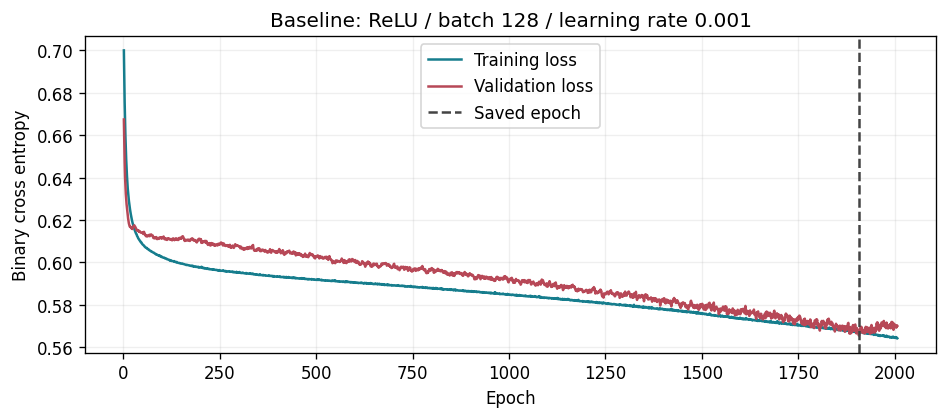

In [8]:
# [실행 보조: 기본 실험 선택]
# True일 때만 새 훈련/W&B 기록/파일 저장을 수행한다. False에서는 기존 JSON만 읽는다.
if RUN_BASELINE:
    baseline = main(make_args(group="hw2-notebook-baseline",
                              output_dir=NEW_RESULTS / "baseline"))
else:
    baseline = load_single_result(RESULTS / "baseline")

# [실행 보조: 표와 링크 출력]
# 저장된 epoch의 loss와 accuracy를 보여준다. 원격 업로드를 끈 실험에는 URL이 없다.
fields = ["activation", "batch_size", "learning_rate", "best_epoch",
          "stopped_epoch", "best_validation_loss", "best_validation_accuracy", "best_validation_f1"]
display(pd.DataFrame([{key: baseline[key] for key in fields}]).T)
if baseline["wandb_url"]:
    display(Markdown("[기본 실험 W&B](" + baseline["wandb_url"] + ")"))


# [실행 보조: 손실 시각화]
def show_loss(record, title):
    """기록의 CSV에서 두 loss를 읽어 Epoch 그래프와 저장 시점 표시를 출력한다."""
    history = pd.read_csv(ROOT / record["history_path"])
    fig, ax = plt.subplots(figsize=(8, 3.6))
    ax.plot(history["Epoch"], history["Training loss"], label="Training loss", color="#167d8d")
    ax.plot(history["Epoch"], history["Validation loss"], label="Validation loss", color="#b74857")
    ax.axvline(record["best_epoch"], color="#444444", linestyle="--", label="Saved epoch")
    ax.set(xlabel="Epoch", ylabel="Binary cross entropy", title=title)
    ax.legend()
    ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()

show_loss(baseline, "Baseline: ReLU / batch 128 / learning rate 0.001")

## 6. 하이퍼파라미터 36개 조합 비교

| 항목 | 비교 값 |
|---|---|
| 활성화 함수 | Sigmoid, ReLU, ELU, Leaky ReLU |
| 배치 크기 | 32, 64, 128 |
| 학습률 | 0.01, 0.001, 0.0001 |

다음 셀에 전체 실험 반복과 결과 집계를 직접 작성했다.
RUN_GRID=False는 이미 완료한 36개 결과를 재사용한다.
True는 새로운 그룹/폴더에서 36개를 학습한다.
모든 설정에서 모델 크기, SGD, seed=42, 최대 10,000 epoch, patience=100, delta=0.00001을 고정한다.

In [9]:
# [실행 보조: 비교할 조합 정의]
# 4*3*3=36개를 생성한다. 원래 shell 스크립트가 하던 반복을 노트북에서 직접 수행한다.
combinations = list(product(
    ["sigmoid", "relu", "elu", "leaky_relu"], [32, 64, 128], [0.01, 0.001, 0.0001]))
grid_dir = RESULTS / "grid"
grid_group = "hw2-20261012-grid"
if RUN_GRID:
    # [실행 보조: 셀 재실행 분리]
    # 셀 재실행이나 실패 뒤 재시작 시 이전 결과와 섞이지 않게 매번 새 ID를 만든다.
    grid_id = datetime.now().strftime("%Y%m%d_%H%M%S") + "_" + uuid4().hex[:8]
    grid_dir = RESULTS / ("notebook_grid_" + grid_id)
    grid_group = "hw2-notebook-grid-" + grid_id
    for activation, batch_size, learning_rate in combinations:
        main(make_args(activation=activation, batch_size=batch_size,
                       learning_rate=learning_rate, group=grid_group, output_dir=grid_dir))

# [실행 보조: 로컬 결과 읽기]
# 선택한 그룹의 JSON만 읽는다. 파일명이 비슷한 다른 실험이나 smoke 결과는 섞지 않는다.
records = []
for path in sorted(grid_dir.glob("*.json")):
    record = json.loads(path.read_text())
    if record.get("group") == grid_group:
        records.append(record)
comparisons = pd.DataFrame(records)

# [실행 보조: 실험 완결성 검사]
# 누락/중복/비정상 loss가 있으면 최적 설정을 고르기 전에 중단한다.
keys = ["activation", "batch_size", "learning_rate"]
assert len(comparisons) == 36, "완료된 실험 36개가 필요함"
assert set(comparisons[keys].itertuples(index=False, name=None)) == set(combinations)
assert not comparisons.duplicated(keys).any(), "중복 조합 발견"
assert np.isfinite(comparisons[["best_validation_loss", "best_validation_accuracy"]]).all().all()
# 저장 모델의 loss가 최소인 것을 선택한다. accuracy는 같은 epoch 값이며 동률일 때만 쓴다.
comparisons = comparisons.sort_values(
    ["best_validation_loss", "best_validation_accuracy", "run_id"],
    ascending=[True, False, True]).reset_index(drop=True)
best = comparisons.iloc[0]
display(comparisons[fields].round(5))
print("확인된 조합:", len(comparisons))
if best.wandb_url:
    display(Markdown("[최적 탐색 실험 W&B](" + best.wandb_url + ")"))

,activation,batch_size,learning_rate,best_epoch,stopped_epoch,best_validation_loss,best_validation_accuracy,best_validation_f1
0,leaky_relu,32,0.0100,626,726,0.38805,85.39326,0.72917
1,elu,32,0.0010,1361,1461,0.38999,86.51685,0.73913
2,relu,64,0.0100,893,993,0.39485,87.07865,0.78095
3,leaky_relu,32,0.0010,1445,1545,0.39485,85.95505,0.74227
4,relu,32,0.0010,1448,1548,0.39519,85.95505,0.74227
5,relu,32,0.0100,431,531,0.40247,83.70786,0.68132
6,elu,64,0.0010,2021,2121,0.40259,82.58427,0.62651
7,elu,64,0.0100,552,652,0.40279,85.95505,0.71910
8,elu,32,0.0100,340,440,0.40297,85.39326,0.74000
9,elu,128,0.0010,3769,3869,0.40674,82.02247,0.62791


확인된 조합: 36


[최적 탐색 실험 W&B](https://wandb.ai/existenceone-korea-university-of-technology-and-education/my_model_training/runs/zq2ojeu8)

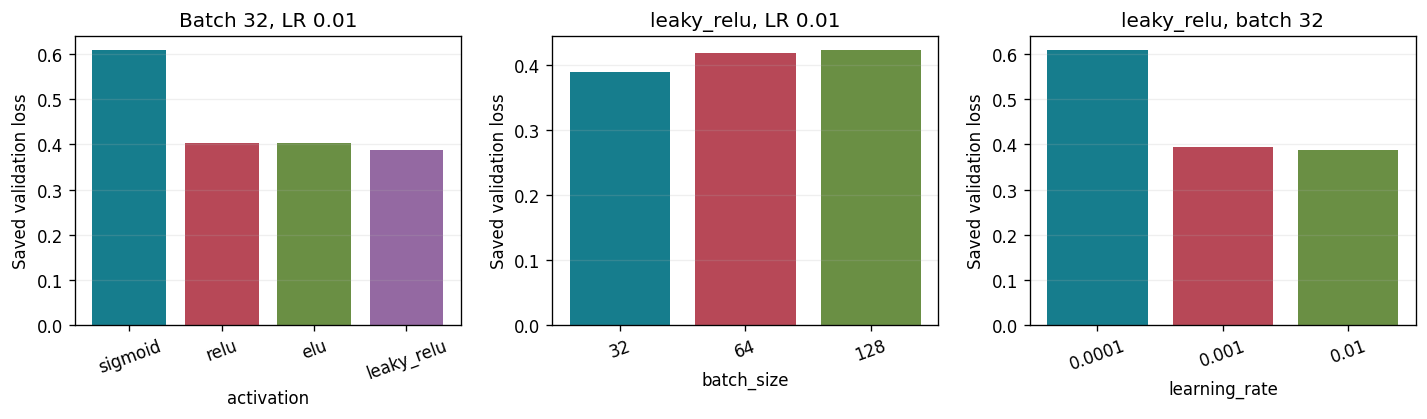

각 그래프는 나머지 두 요인을 최적 설정으로 고정한 비교임. 낮은 loss가 좋음.


In [10]:
# [실행 보조: 요인별 비교 시각화]
# 다른 두 요인을 최적 설정으로 고정하고 한 요인만 바꾼 loss를 막대로 비교한다.
# 행렬은 다음 셀의 36개 조합 heatmap에 사용하며, 여기서는 표/파일을 저장하지 않는다.
activation_order = ['sigmoid', 'relu', 'elu', 'leaky_relu']
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
comparisons['setting'] = comparisons.activation + ' / bs' + comparisons.batch_size.astype(str)
matrix = comparisons.pivot(index='setting', columns='learning_rate', values='best_validation_loss')
for ax, (field, selected, title) in zip(axes, [
    ('activation', comparisons[(comparisons.batch_size == best.batch_size) &
        (comparisons.learning_rate == best.learning_rate)].set_index('activation').loc[activation_order],
     f'Batch {best.batch_size}, LR {best.learning_rate:g}'),
    ('batch_size', comparisons[(comparisons.activation == best.activation) &
        (comparisons.learning_rate == best.learning_rate)].sort_values('batch_size').set_index('batch_size'),
     f'{best.activation}, LR {best.learning_rate:g}'),
    ('learning_rate', comparisons[(comparisons.activation == best.activation) &
        (comparisons.batch_size == best.batch_size)].sort_values('learning_rate').set_index('learning_rate'),
     f'{best.activation}, batch {best.batch_size}'),
]):
    ax.bar([str(x) for x in selected.index], selected.best_validation_loss,
           color=['#167d8d', '#b74857', '#6a8f44', '#9469a2'][:len(selected)])
    ax.set(xlabel=field, ylabel='Saved validation loss', title=title)
    ax.tick_params(axis='x', labelrotation=20)
    ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
plt.show()
print('각 그래프는 나머지 두 요인을 최적 설정으로 고정한 비교임. 낮은 loss가 좋음.')

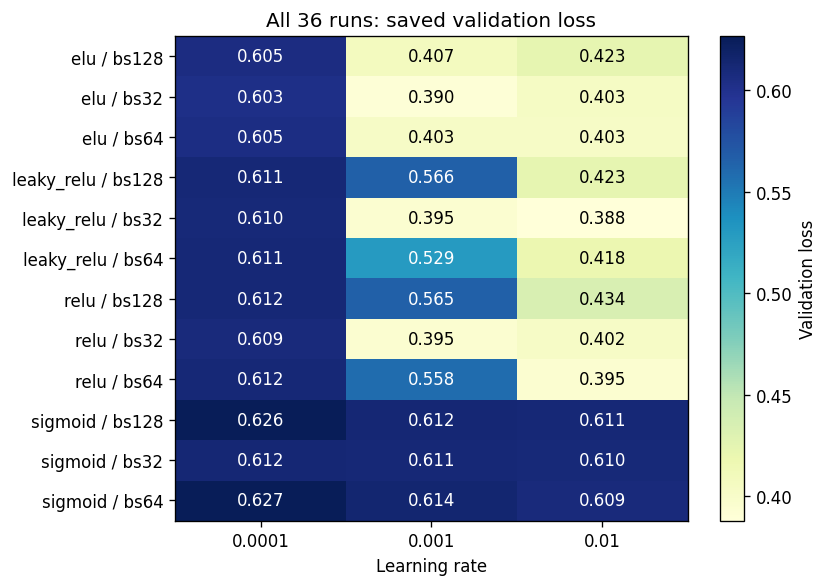

최저 검증 손실 설정은 **leaky_relu, batch=32, learning rate=0.01**이며, loss는 **0.38805**, 같은 모델의 검증 정확도는 **85.39%**이다. 총 1개 실험은 최대 epoch에 도달했다. 따라서 비교 결과는 같은 훈련 예산과 현재 분할에서의 결과이며, 모든 설정이 충분히 수렴했다는 뜻은 아니다.

저장 모델 중 최고 검증 정확도는 relu, batch=64, learning rate=0.01의 **87.08%**이다. 정확도와 교차 엔트로피는 서로 다른 지표이므로 순위가 같지 않을 수 있다. 본 실험은 미리 정한 검증 손실 기준을 유지해 최종 모델을 선택했다. 기본 모델 loss 0.56549에서 선택 모델 loss 0.38805로 개선되었다.

In [11]:
# [실행 보조: 전체 결과 시각화와 해석]
# 12개 활성화/배치 조합과 3개 학습률의 loss를 색과 수치로 표시한다.
# 학습 예산 도달 여부 및 loss 기준 선택과 accuracy 기준 순위의 차이를 함께 출력한다.
fig, ax = plt.subplots(figsize=(7, 5))
heat = ax.imshow(matrix.values, cmap='YlGnBu', aspect='auto')
ax.set_xticks(range(len(matrix.columns)), [f'{x:g}' for x in matrix.columns])
ax.set_yticks(range(len(matrix.index)), matrix.index)
for row in range(len(matrix)):
    for col in range(len(matrix.columns)):
        value = matrix.iloc[row, col]
        ax.text(col, row, f'{value:.3f}', ha='center', va='center',
                color='white' if value > (matrix.values.max()+matrix.values.min())/2 else 'black')
ax.set(xlabel='Learning rate', title='All 36 runs: saved validation loss')
fig.colorbar(heat, ax=ax, label='Validation loss')
fig.tight_layout()
plt.show()
reached_limit = int((comparisons.stopped_epoch == comparisons.max_epochs).sum())
display(Markdown(
    f'최저 검증 손실 설정은 **{best.activation}, batch={best.batch_size}, '
    f'learning rate={best.learning_rate:g}**이며, loss는 **{best.best_validation_loss:.5f}**, '
    f'같은 모델의 검증 정확도는 **{best.best_validation_accuracy:.2f}%**이다. '
    f'총 {reached_limit}개 실험은 최대 epoch에 도달했다. '
    '따라서 비교 결과는 같은 훈련 예산과 현재 분할에서의 결과이며, 모든 설정이 충분히 수렴했다는 뜻은 아니다.'))
accuracy_best = comparisons.sort_values('best_validation_accuracy', ascending=False).iloc[0]
display(Markdown(
    f'저장 모델 중 최고 검증 정확도는 {accuracy_best.activation}, '
    f'batch={accuracy_best.batch_size}, learning rate={accuracy_best.learning_rate:g}의 '
    f'**{accuracy_best.best_validation_accuracy:.2f}%**이다. '
    '정확도와 교차 엔트로피는 서로 다른 지표이므로 순위가 같지 않을 수 있다. '
    '본 실험은 미리 정한 검증 손실 기준을 유지해 최종 모델을 선택했다. '
    f'기본 모델 loss {baseline["best_validation_loss"]:.5f}에서 '
    f'선택 모델 loss {best.best_validation_loss:.5f}로 개선되었다.'))

## 7. 최적 설정과 모델 복원

완료한 실험에서는 Leaky ReLU, batch=32, learning rate=0.01이 가장 낮은 저장 검증 손실을 보였다.
기본 실행은 기존 최종 모델을 복원한다. RUN_FINAL=True이거나 새 grid를 수행했다면
현재 선택한 설정으로 최종 모델을 새로 훈련한다.
종료 시점의 모델이 아니라 명시된 최적 checkpoint를 사용한다.

,0
activation,leaky_relu
batch_size,32
learning_rate,0.01
best_epoch,626
stopped_epoch,726
best_validation_loss,0.388047
best_validation_accuracy,85.393256
best_validation_f1,0.729167


예측용 epoch: 626 | 학습 종료 epoch: 726


[최종 모델 W&B](https://wandb.ai/existenceone-korea-university-of-technology-and-education/my_model_training/runs/wyso2kzp)

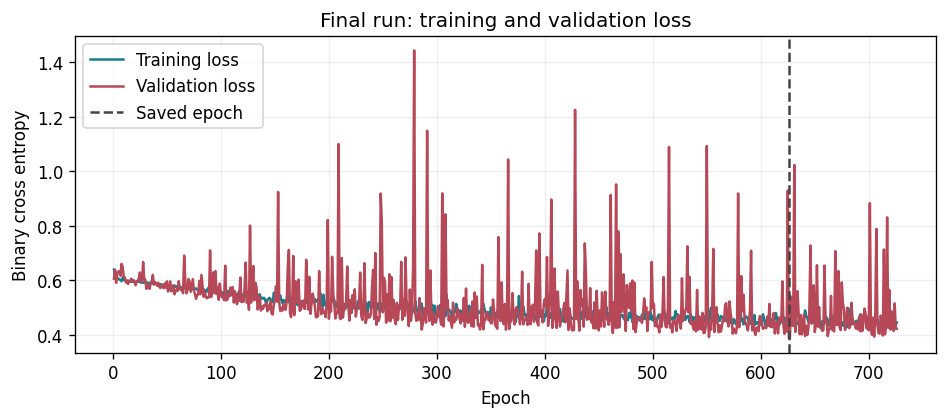

복원 검증: loss=0.388047, accuracy=85.39%, F1=0.7292


In [12]:
# [실행 보조: 최종 실행 선택]
# grid를 새로 돌렸다면 이전 final과 섞지 않고 선택된 설정으로 새 final을 만든다.
if RUN_FINAL or RUN_GRID:
    final = main(make_args(
        activation=best.activation, batch_size=int(best.batch_size),
        learning_rate=float(best.learning_rate),
        group="hw2-notebook-final-" + REPEAT_ID, output_dir=NEW_RESULTS / "final"))
else:
    final = load_single_result(RESULTS / "final")
assert all(final[key] == best[key] for key in keys), "선택 설정과 final 모델이 다름"
display(pd.DataFrame([{key: final[key] for key in fields}]).T)
print("예측용 epoch:", final["best_epoch"], "| 학습 종료 epoch:", final["stopped_epoch"])
if final["wandb_url"]:
    display(Markdown("[최종 모델 W&B](" + final["wandb_url"] + ")"))
show_loss(final, "Final run: training and validation loss")


# [핵심: 저장된 모델 복원]
def restore_model(record):
    """실험 설정과 명시된 checkpoint로 MLP를 복원하여 평가 모드로 반환한다."""
    config = SimpleNamespace(activation=record["activation"],
                             n_hidden_unit_list=record["hidden_sizes"])
    model = MyModel(10, 1, SimpleNamespace(config=config))
    # latest가 아니라 해당 실험의 가중치를 로드한다. 상대 경로는 프로젝트 루트 기준이다.
    model.load_state_dict(torch.load(
        ROOT / record["checkpoint_path"], map_location="cpu", weights_only=True))
    model.eval()
    return model

# [실행 보조: 복원 성능 확인]
# 새로 훈련했다고 표현하지 않고, 복원한 모델의 loss/accuracy/F1이 기록과 일치하는지 검증한다.
restored = restore_model(final)
validation = next(iter(DataLoader(validation_set, batch_size=len(validation_set))))
with torch.no_grad():
    logits = restored(validation["input"])
    targets = validation["target"].float().unsqueeze(1)
    restored_loss = nn.functional.binary_cross_entropy_with_logits(logits, targets).item()
restored_accuracy, restored_f1 = binary_accuracy_f1(logits, targets)
assert abs(restored_loss - final["best_validation_loss"]) < 1e-6
assert abs(restored_accuracy - final["best_validation_accuracy"]) < 1e-6
assert abs(restored_f1 - final["best_validation_f1"]) < 1e-6
print(f"복원 검증: loss={restored_loss:.6f}, accuracy={restored_accuracy:.2f}%, F1={restored_f1:.4f}")

## 8. 테스트 예측과 제출 파일

테스트 DataLoader는 원본 행 순서를 유지한다. PassengerId는 원본 test.csv에서 가져오며,
logit이 0 이상이면 생존 1로 판정한다. 출력은 PassengerId, Survived 두 열의 418행이다.
이미 제출한 파일을 보존하기 위해 재현 결과가 동일한지 확인하고, 다르면 별도 파일로 저장한다.

In [13]:
# [핵심: 테스트 예측]
def predict_submission(record, output_path):
    """실험 기록으로 모델을 복원하고 418명의 이진 예측을 검증한 뒤 CSV를 저장한다."""
    model = restore_model(record)
    _, _, test_dataset = get_preprocessed_dataset(record["seed"])
    # 순서를 섞으면 원본 PassengerId와 예측의 대응이 깨지므로 shuffle=False로 고정한다.
    test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)
    with torch.no_grad():
        logits = torch.cat([model(batch["input"]).reshape(-1) for batch in test_loader])
    assert torch.isfinite(logits).all(), "유한하지 않은 예측값"
    ids = pd.read_csv(DATA_DIR / "test.csv")["PassengerId"]
    result = pd.DataFrame({"PassengerId": ids, "Survived": (logits >= 0).long().numpy()})

    # [실행 보조: 제출 형식 검증]
    # 행 수/중복/결측값을 검사한 후 index=False로 불필요한 인덱스 열 없이 저장한다.
    assert len(result) == len(test_dataset) == 418
    assert not result.isna().any().any() and not ids.duplicated().any()
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    result.to_csv(output_path, index=False)
    return result

# [실행 보조: 기존 제출 파일 보존]
# 재현 파일은 별도 이름으로 생성한다. 기존 submission.csv는 읽기만 하며 덮어쓰지 않는다.
reproduced_path = DATA_DIR / "submission_reproduced.csv"
submission = predict_submission(final, reproduced_path)
submitted_path = DATA_DIR / "submission.csv"
assert list(submission.columns) == ["PassengerId", "Survived"]
assert submission.PassengerId.tolist() == raw_test.PassengerId.tolist()
assert set(submission.Survived.unique()).issubset({0, 1})
if submitted_path.exists():
    submitted = pd.read_csv(submitted_path)
    matches = submission.equals(submitted)
    print("이미 제출한 CSV와 전체 예측 일치:", matches)
    if not (RUN_FINAL or RUN_GRID):
        assert matches, "기존 모델 재현 결과가 다름: 제출 파일을 보존하고 원인 확인 필요"
else:
    print("기존 제출 파일 없음: 재현 CSV만 생성됨")
display(submission.head(10))
display(submission.Survived.value_counts().sort_index().rename("예측 인원").to_frame())
print("재현 CSV:", reproduced_path)
print("형식 검증 완료: 418행, 원본 ID 순서, 두 열, 0/1 예측")

이미 제출한 CSV와 전체 예측 일치: True


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1
5,897,0
6,898,1
7,899,0
8,900,1
9,901,0


,예측 인원
Survived,
0,271
1,147


재현 CSV: /Users/jyj/git/link_dl/_03_homeworks/homework_2/submission_reproduced.csv
형식 검증 완료: 418행, 원본 ID 순서, 두 열, 0/1 예측


## 9. Kaggle 제출 결과

- Kaggle 사용자: ExistenceOne
- 제출 점수: 0.74880 (정확도 74.880%)
- 캡처 시점 순위: 9,984위

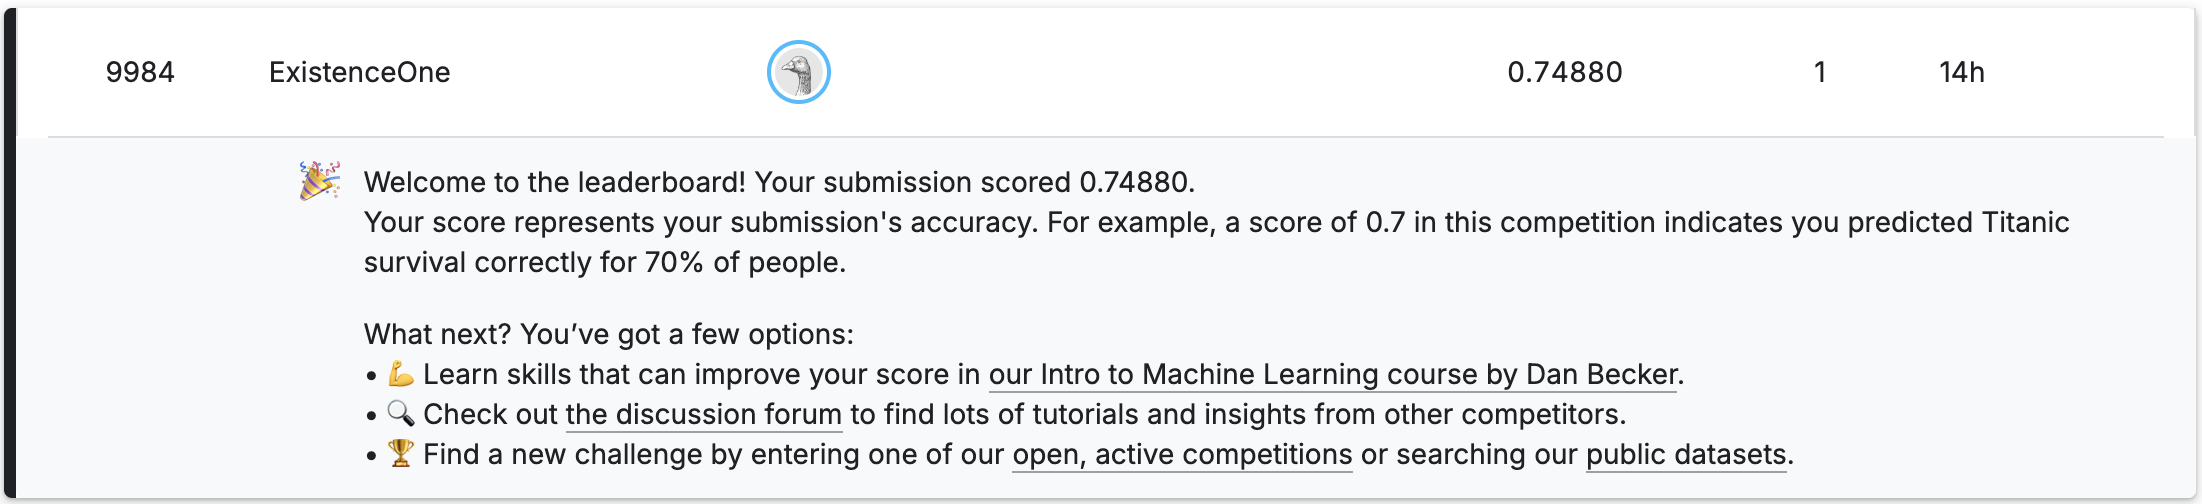

## 10. 기술적 고찰

- 배치 크기가 달라지면 epoch당 갱신 횟수도 달라진다. 같은 epoch 수가 같은 SGD 갱신 횟수를 뜻하지는 않는다.
- 배치 손실의 단순 평균은 마지막 배치가 작은 경우 표본당 평균과 다르다. 표본 수로 가중해 비교 기준을 맞췄다.
- 최고 accuracy epoch와 최저 loss epoch는 다를 수 있다. 체크포인트와 같은 epoch의 지표를 함께 저장해야 보고와 추론이 일치한다.
- 첫 epoch 이후 성능이 악화되는 경우에도 예측이 가능하도록 초기 체크포인트를 저장해야 한다.
- 분할 RNG와 셔플 RNG를 분리하면 노트북에서 다른 난수를 생성해도 실험 분할이 바뀌지 않는다.
- 강의 제공 전처리는 train/test를 합쳐 결측값 통계와 범주 인코딩을 산출한다. 테스트 정답을 사용하지는 않지만 검증/테스트 입력 분포를 미리 참조한다. 엄격한 일반화 평가에서는 train 분할로만 전처리를 학습하고 나머지에는 적용해야 한다.
- 이번 실험은 단일 검증 분할로 36개 설정을 선택했으므로 그 분할에 대한 선택 편향이 있다. 반복 seed나 교차 검증을 수행한 결과로 일반화하면 안 된다.
- 특성 스케일은 강의 코드대로 유지했으므로 Fare와 Age의 크기가 최적화에 영향을 줄 수 있다. 정규화의 효과는 이번 비교에서 검증하지 않았다.

## 숙제 후기

이번 과제에서는 활성화 함수, 배치 크기, 학습률을 바꾼 36개 조합을 비교했다. 같은 모델 구조에서도 설정에 따라 성능과 학습 과정이 달라지는 것을 확인하면서, 하나의 설정만으로 결과를 판단하기보다 여러 조합을 비교하는 것이 중요하다고 느꼈다.

특히 검증 정확도가 가장 높은 설정과 검증 loss가 가장 낮은 설정이 서로 달랐던 점이 인상적이었다. 이를 통해 정답 여부를 평가하는 정확도와 예측 확률까지 반영하는 BCE loss의 차이를 이해했고, 모델을 선택할 때 기준 지표를 명확히 해야 한다는 점을 배웠다.

Early Stopping을 적용한 최종 학습은 726 epoch에서 종료되었지만, 실제 예측에는 최적 시점인 626 epoch의 가중치를 사용했다. 이 과정을 통해 학습을 오래 진행하는 것만큼 검증 성능이 좋은 가중치를 저장하고 복원하는 것이 중요하다는 점을 확인했다.

마지막으로 검증 정확도는 약 85.39%였지만 Kaggle 점수는 74.88%로 차이가 있었다. 정확한 원인을 이번 실험만으로 판단할 수는 없지만, 한 번의 검증 결과가 새로운 데이터에서의 성능을 그대로 보장하지는 않는다는 점을 느꼈다. 다음에는 여러 seed나 교차검증을 활용해 결과가 얼마나 일관되게 유지되는지도 확인해 보고 싶다.